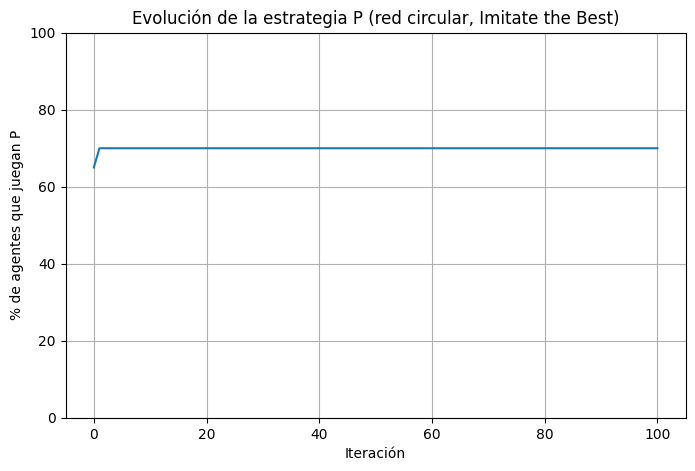

Porcentaje final de agentes con P: 70.0 %


In [1]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

# Semilla para que los resultados se puedan repetir
np.random.seed(42)

# Parámetros
N = 20            # número de agentes
T = 100           # número de iteraciones

# Matriz de pagos (fila = mi estrategia, columna = estrategia del vecino)
# 0 = P, 1 = R
pagos = np.array([[1.0, 0.0],
                  [0.5, 0.7]])

# 1. Inicializar la red (círculo)
G = nx.cycle_graph(N)

# 2. Asignar estrategia aleatoria a cada agente
estrategias = np.random.randint(0, 2, size=N)

# Aquí guardo el % de agentes que juegan P en cada iteración
porcentaje_P = []
porcentaje_P.append(np.mean(estrategias == 0) * 100)  # estado inicial

# 3. Bucle principal
for t in range(T):

    # Cada agente juega con todos sus vecinos y suma sus beneficios
    beneficios = np.zeros(N)
    for i in G.nodes():
        for vecino in G.neighbors(i):
            beneficios[i] += pagos[estrategias[i], estrategias[vecino]]

    # Cada agente observa a sus vecinos y copia al que más ha ganado
    # (Imitate the Best). También compara con su propio beneficio.
    nuevas_estrategias = estrategias.copy()
    for i in G.nodes():
        candidatos = list(G.neighbors(i)) + [i]
        mejor_beneficio = max(beneficios[j] for j in candidatos)
        mejores = [j for j in candidatos if beneficios[j] == mejor_beneficio]
        elegido = np.random.choice(mejores)   # si hay empate, al azar
        nuevas_estrategias[i] = estrategias[elegido]

    # Actualización simultánea
    estrategias = nuevas_estrategias

    # Registrar el % de agentes que juegan P
    porcentaje_P.append(np.mean(estrategias == 0) * 100)

# 4. Gráfico
plt.figure(figsize=(8, 5))
plt.plot(porcentaje_P)
plt.xlabel("Iteración")
plt.ylabel("% de agentes que juegan P")
plt.title("Evolución de la estrategia P (red circular, Imitate the Best)")
plt.ylim(0, 100)
plt.grid(True)
plt.show()

print("Porcentaje final de agentes con P:", porcentaje_P[-1], "%")